# 03 -- Demand forecasting: LightGBM vs. baselines

Target: weekly units at brand x pack x store, 1-8 weeks ahead. Rolling-origin backtest with 9 folds
(origins every 8 weeks, test weeks 328-399). Code: `beverage_demand.forecasting.backtest`.
Planned price and promotion for the target week are treated as known in advance.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from beverage_demand.config import results, figure
from beverage_demand.config import processed
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

## 1. Tuning LightGBM with time-series cross-validation

8 settings from a small grid, each scored on 3 time-based folds that lie *before* the backtest
period (`beverage_demand.forecasting.tuning`). Every trial is saved to `results/tuning_trials.csv`.

In [2]:
pd.read_csv(results("tuning_trials.csv")).round(4)

,trial,tweedie_variance_power,num_leaves,min_data_in_leaf,wape_fold0,wape_fold1,wape_fold2,cv_wape,rounds,seconds
0,6,1.7,127,50,0.440,0.535,0.418,0.465,300,74
1,7,1.7,127,200,0.461,0.518,0.422,0.467,55,73
2,3,1.5,127,50,0.474,0.524,0.419,0.472,44,77
3,1,1.2,127,200,0.450,0.550,0.433,0.477,299,255
4,4,1.7,31,50,0.485,0.530,0.424,0.480,49,47
5,5,1.7,31,200,0.475,0.531,0.433,0.480,56,48
6,2,1.5,31,50,0.489,0.531,0.427,0.482,51,83
7,0,1.2,31,50,0.493,0.572,0.462,0.509,45,155


Deeper trees (127 leaves) and a Tweedie power of 1.7 work best: weekly volumes are spiky
(huge promotion weeks, many small weeks), and a higher Tweedie power treats large values as
naturally more variable.

## 2. Backtest: LightGBM vs. three baselines

Each of the 9 folds trains on everything before its origin week and forecasts the next 8 weeks.

In [3]:
m = pd.read_csv(results("forecast_metrics.csv"))
m[m["slice"].isin(["overall", "promo", "chain_level"])].pivot_table(index=["slice", "group"], columns="model", values="wape").round(3)

model                          lightgbm  moving_avg_4  regression  seasonal_naive
slice       group                                                                
chain_level all series x week     0.427         0.960       0.519           0.881
overall     all                   0.473         0.976       0.580           0.908
promo       non-promo weeks       0.402         2.737       0.449           1.975
            promo weeks           0.483         0.742       0.598           0.766

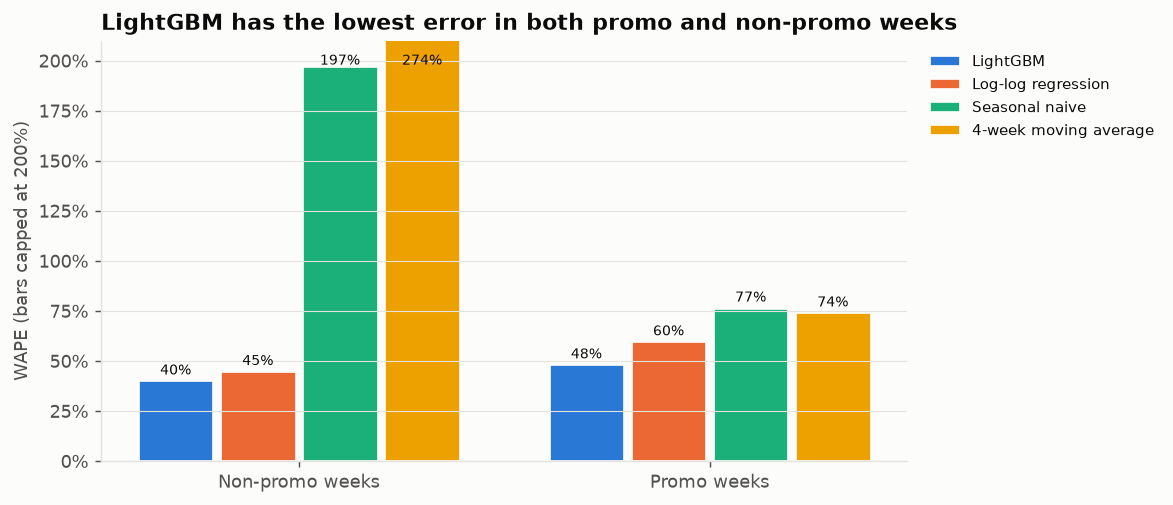

In [4]:
Image(filename=str(figure("forecast_wape_promo_split.png")))

**So what:** LightGBM has the lowest error overall and in promotion weeks. Naive baselines are
useless here because volume swings roughly 5-20x between promoted and normal weeks; the log-log regression
is a solid baseline in normal weeks but loses accuracy in promo weeks, where LightGBM's
interactions between discount depth, promo type and recent sales help most.

In [5]:
m[m["slice"] == "series"].pivot_table(index="group", columns="model", values="wape").round(3)

model,lightgbm,moving_avg_4,regression,seasonal_naive
group,,,,
7Up | 24pk can,0.677,1.248,0.743,1.145
7Up | 2L,0.431,0.942,0.391,0.782
Coke | 24pk can,0.624,1.031,0.993,0.921
Coke | 2L,0.486,0.808,0.467,0.809
Diet Coke | 24pk can,0.600,1.026,0.846,0.930
Diet Coke | 2L,0.484,0.777,0.428,0.778
Diet Pepsi | 24pk can,0.449,0.996,0.744,1.010
Diet Pepsi | 2L,0.458,0.919,0.439,0.868
Pepsi | 24pk can,0.500,1.015,0.905,1.011


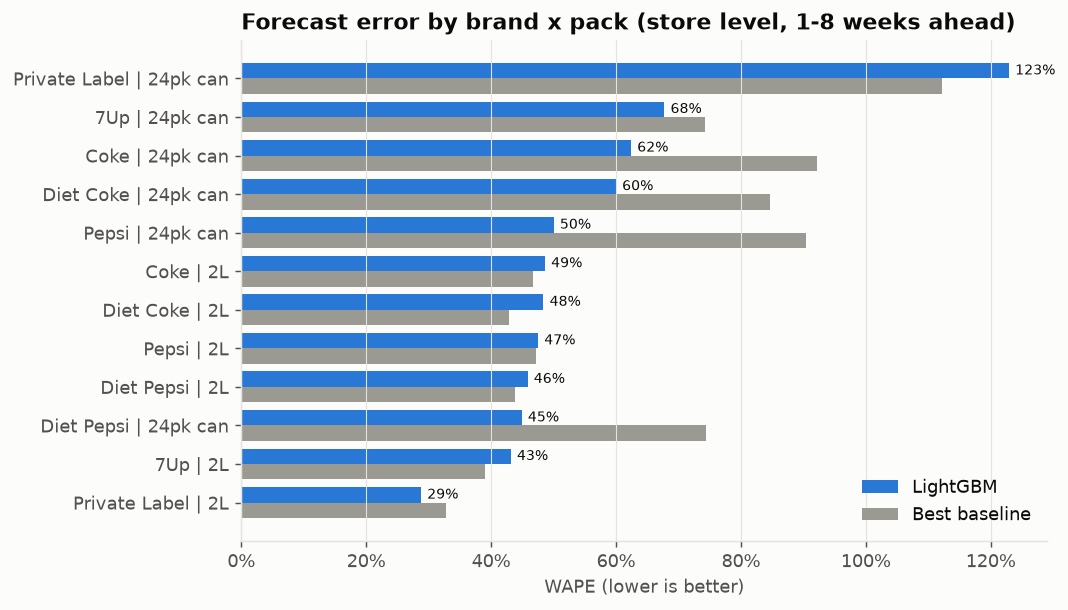

In [6]:
Image(filename=str(figure("forecast_wape_by_series.png")))

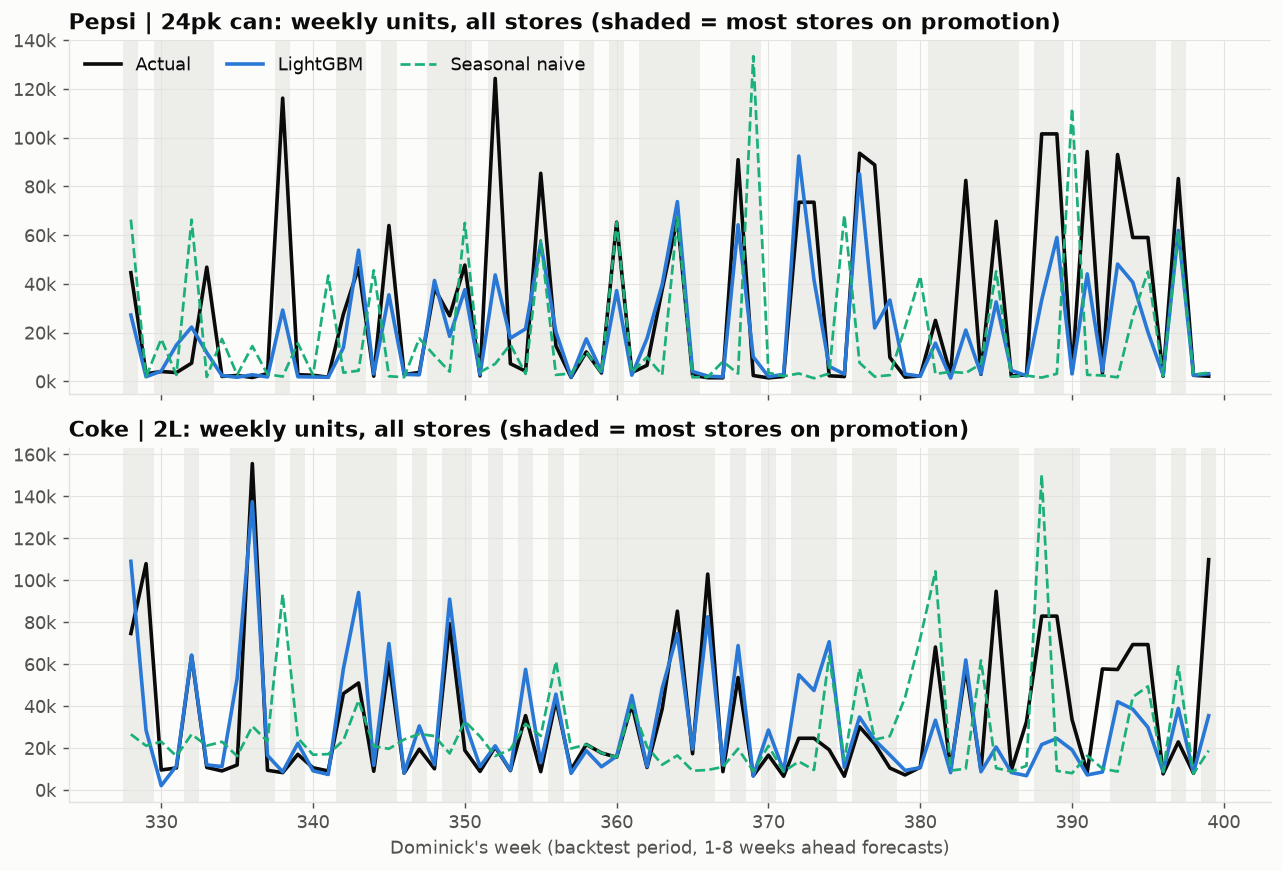

In [7]:
Image(filename=str(figure("forecast_actual_vs_forecast.png")))

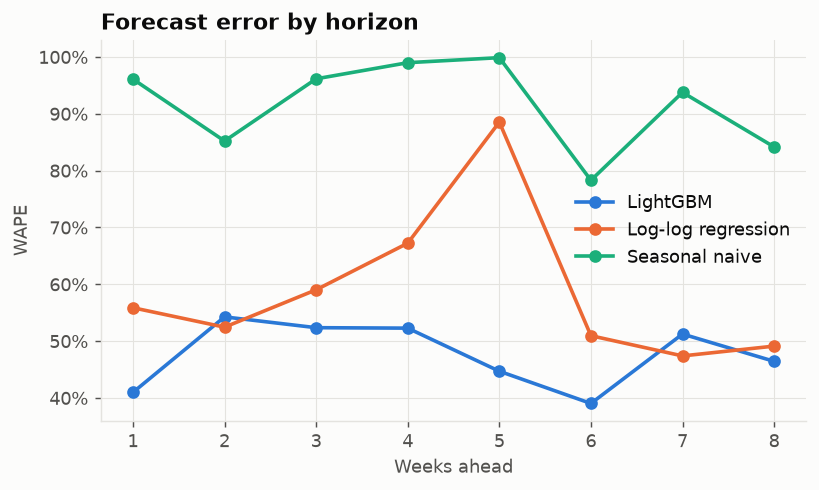

In [8]:
Image(filename=str(figure("forecast_wape_by_horizon.png")))

## 3. What drives the forecast (SHAP)

In [9]:
pd.read_csv(results("forecast_shap_importance.csv")).head(12)

,Unnamed: 0,mean_abs_shap
0,discount depth,0.709
1,13-wk avg sales,0.411
2,own price (log),0.326
3,brand x pack,0.206
4,promo_u,0.143
5,regular price (log),0.114
6,price vs competitors,0.070
7,sin1,0.066
8,cos2,0.052
9,competitor discount,0.052


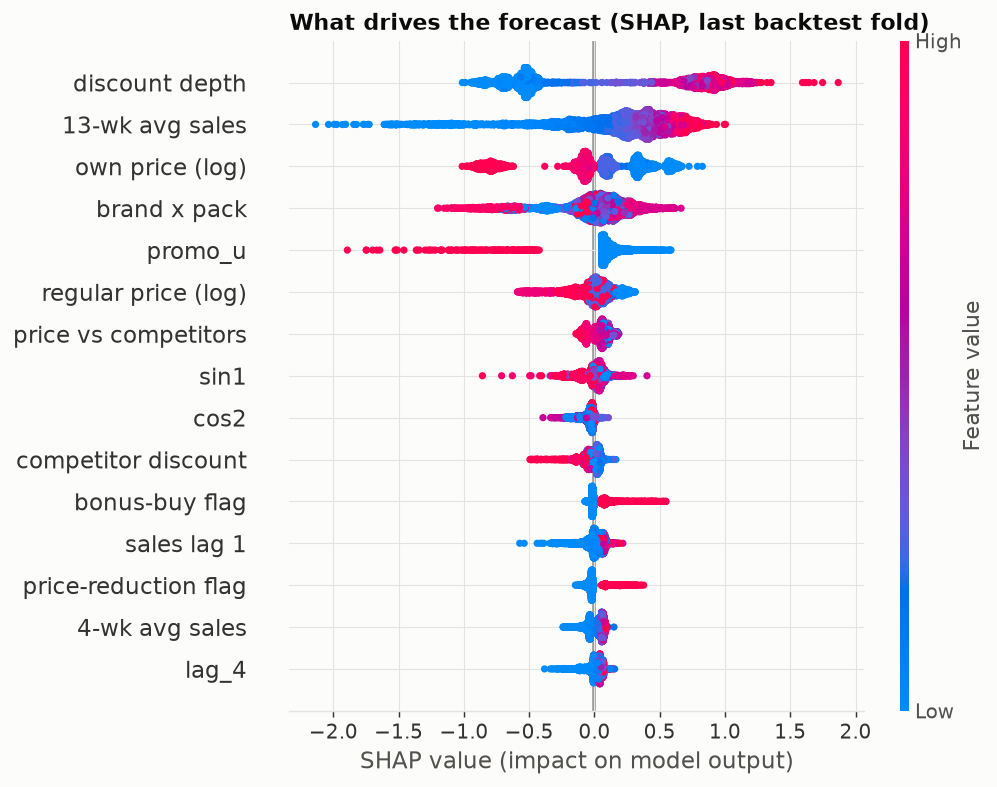

In [10]:
Image(filename=str(figure("forecast_shap_summary.png")))

**So what:** Discount depth is by far the biggest driver of next week's volume, followed by the
store's recent sales level and the price itself. In this category a forecast that does not know
the promotion plan cannot be accurate -- which is why sales and demand-planning teams need to share
the promo calendar.